In [22]:
# Experiment to test the performance of different IP forward models from MPA and Cole  

import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import numpy as np
import torch

from anemone.experiment import *
from anemone.forwards import *
from anemone.inversion import SmoothModelColeCole, FewLayerColeCole

In [23]:
tx = Loop.square(3)
rx = Receiver(x=13)
waveform = Waveform.example()
recfilter = FilterChain([ButterworthFilter(2.4e5,1),
                         ButterworthFilter(6.2e5,1),
                         ButterworthFilter(4.5e5,1)])

In [24]:
# Define the MPA model characteristics, Transmitter and Receiver size and position
# and the waveform to be used. 
times = torch.logspace(-5, -3, 32)
fwrTD = Forward.mpa(tx, rx, times, filterfunc=recfilter)


frqs = torch.logspace(3,6,51)
fwrFD = ForwardFD.mpa(tx, rx, frqs, filterfunc=recfilter)

In [25]:
# Define the model parameters fopr the MPA model. 


rho = torch.tensor([1000,10], dtype=torch.double)
#tau_phi = torch.tensor([1e-4, 1e-4], dtype=torch.double)
#c= torch.tensor([0.6, 0.6], dtype=torch.double)

thickness = torch.tensor([30], dtype=torch.double)

# Ip values for the MPA model in the second layer
phi_max_values = torch.logspace(start=torch.log10(torch.tensor(1)), 
                            end=torch.log10(torch.tensor(1000.0)), 
                            steps=10, dtype=torch.double)/1e3

tau_phi_values = torch.logspace(start=torch.log10(torch.tensor(1e-5)),
                            end=torch.log10(torch.tensor(1e-2)), 
                            steps=10, dtype=torch.double)

c_values = torch.tensor([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], dtype=torch.double)

phi_2 = torch.tensor(0.001, dtype=torch.double)
tau_phi_2 = 1e-4
c_2 = 0.5

# Reference model to compute all the % changes
rho_ref = torch.tensor([1000, 10], dtype=torch.double)
phi_ref = torch.tensor([phi_max_values[0].item(), phi_2], dtype=torch.double)
tau_phi_ref = torch.tensor([tau_phi_values[0].item(), tau_phi_2], dtype=torch.double)
c_ref = torch.tensor([c_values[0].item(), c_2], dtype=torch.double)

# Compute the refence forward model
dbdt_ref = fwrTD(rho_ref, phi_ref, tau_phi_ref, c_ref, thickness)
dbdf_ref = fwrFD(rho_ref, phi_ref, tau_phi_ref, c_ref, thickness)


# Colormap
cmap = cm.get_cmap('rainbow')
norm = mcolors.Normalize(vmin=float(c_values.min()), vmax=float(c_values.max()))
sm = cm.ScalarMappable(cmap=cmap, norm=norm)



C:\Users\au653994\AppData\Local\Temp\ipykernel_21680\3004111472.py:37: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('rainbow')


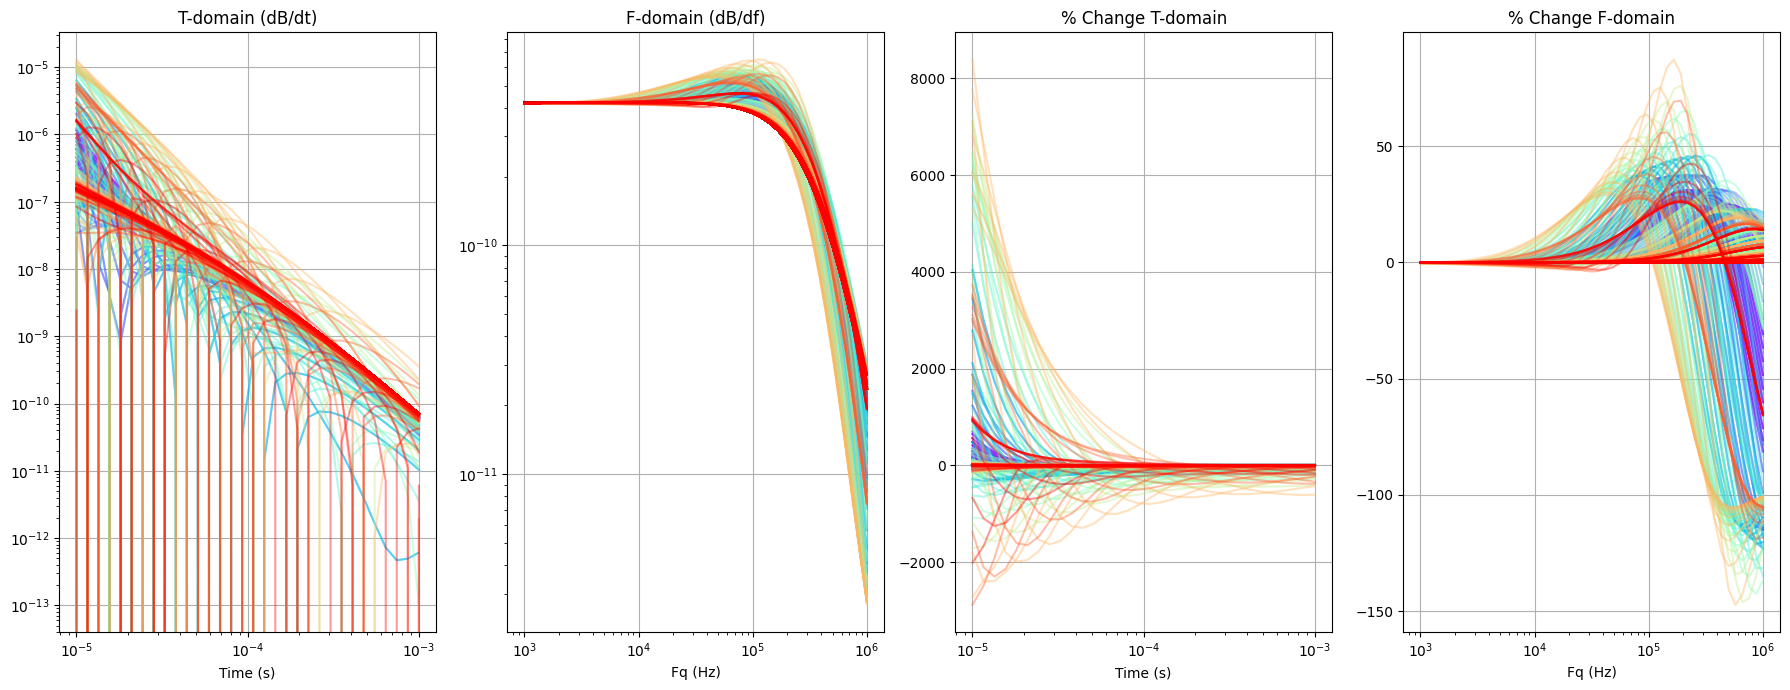

In [26]:


fig,axs = plt.subplots(1, 4, figsize=(18, 7))

for c0 in c_values:
    color = cmap(norm(c0.item()))

    for phi0 in phi_max_values:
        for tau0 in tau_phi_values:
            phi_max = torch.tensor([phi0.item(), phi_2.item()], dtype=torch.double)
            tau_phi = torch.tensor([tau0.item(), tau_phi_2], dtype=torch.double)
            c = torch.tensor([c0.item(), c_2], dtype=torch.double)

            # Compute the model response for the MPA model
            dbdt = fwrTD(rho, phi_max, tau_phi, c, thickness)
            dbdf = fwrFD(rho, phi_max, tau_phi, c, thickness)

            # Plot the results
            axs[0].loglog(times, dbdt, color=color, linestyle='-', alpha=0.4)
            axs[0].loglog(times, -dbdt, color=color, linestyle='-', alpha=0.4)
            axs[1].loglog(frqs, torch.abs(dbdf), color=color, linestyle='-', alpha=0.4)

            # Percentage change plots
            pct_change_dbdt = ((dbdt - dbdt_ref) / dbdt_ref) * 100
            pct_change_dbdf = ((dbdf - dbdf_ref) / dbdf_ref) * 100

            axs[2].semilogx(times, pct_change_dbdt, color=color, alpha=0.4)
            axs[3].semilogx(frqs, pct_change_dbdf, color=color, alpha=0.4)


# Label and layout
axs[0].set_title("T-domain (dB/dt)")
axs[1].set_title("F-domain (dB/df)")
axs[2].set_title("% Change T-domain")
axs[3].set_title("% Change F-domain")

axs[0].set_xlabel('Time (s)')
axs[1].set_xlabel('Fq (Hz)')
axs[2].set_xlabel('Time (s)')
axs[3].set_xlabel('Fq (Hz)')

for ax in axs:
    ax.grid(True)

savefig = True

plt.tight_layout()

if savefig:
    plt.savefig(r'c:\Users\au653994\OneDrive - Aarhus universitet\Documents\PhD\anemone\Figures\2L_IP_Var\MPA_1000_10.png', dpi=300, bbox_inches='tight')